Using device: cuda
Preparing data...
Model architecture:
SimpleDNN(
  (network): Sequential(
    (0): Linear(in_features=1, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=64, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.2, inplace=False)
    (12): Linear(in_features=64, out_features=1, bias=True)
  )
)

Starting training...
Epoch [10/100], Loss: 1.7142
Epoch [20/100], Loss: 1.5968
Epoch [30/100], Loss: 1.4952
Epoch [40/100], Loss: 1.1225
Epoch [50/100], Loss: 1.1863
Epoch [60/100], Loss: 1.1995
Epoch [70/100], Loss: 1.0830


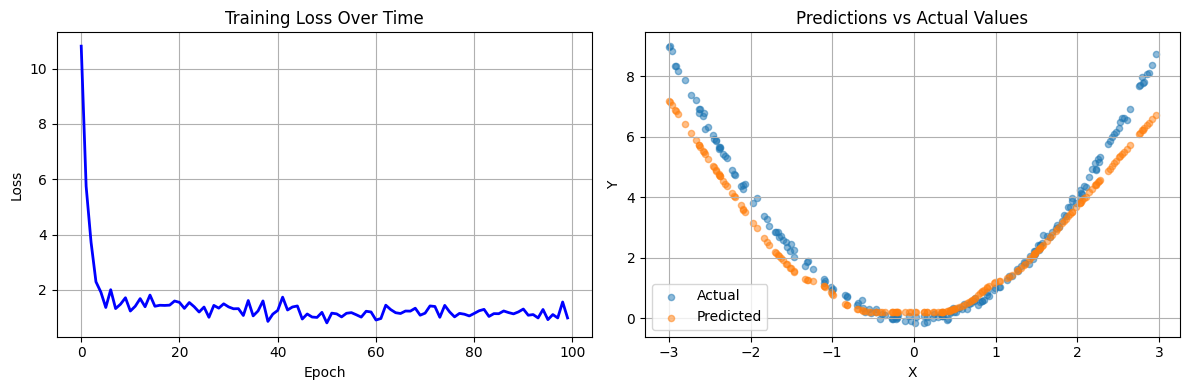


Model saved as 'simple_dnn_model.pth'

Testing loaded model with new data:
x = 2.50, predicted y = 5.2820
x = -1.50, predicted y = 1.6205
x = 0.00, predicted y = 0.2083


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt

# ==================== 1. 定义DNN网络结构 ====================
class SimpleDNN(nn.Module):
    """
    一个简单的深度神经网络模型
    用于回归任务：预测 y = x^2 + 噪声
    """
    def __init__(self, input_size, hidden_sizes, output_size):
        """
        初始化网络层
        
        参数:
        input_size: 输入特征维度
        hidden_sizes: 隐藏层维度列表
        output_size: 输出维度
        """
        super(SimpleDNN, self).__init__()
        
        # 构建网络层
        layers = []
        
        # 输入层到第一个隐藏层
        prev_size = input_size
        for i, hidden_size in enumerate(hidden_sizes):
            # 全连接层
            layers.append(nn.Linear(prev_size, hidden_size))
            # 批归一化（可选，帮助训练稳定）
            layers.append(nn.BatchNorm1d(hidden_size))
            # 激活函数（引入非线性）
            layers.append(nn.ReLU())
            # Dropout（防止过拟合）
            layers.append(nn.Dropout(0.2))
            prev_size = hidden_size
        
        # 输出层
        layers.append(nn.Linear(prev_size, output_size))
        
        # 将层序列组合成网络
        self.network = nn.Sequential(*layers)
        
    def forward(self, x):
        """
        前向传播
        
        参数:
        x: 输入张量，形状 (batch_size, input_size)
        
        返回:
        预测值，形状 (batch_size, output_size)
        """
        return self.network(x)


# ==================== 2. 准备数据 ====================
def prepare_data():
    """
    生成示例数据：y = x^2 + 噪声
    """
    # 设置随机种子以便结果可重复
    torch.manual_seed(42)
    np.random.seed(42)
    
    # 生成输入数据
    X = np.linspace(-3, 3, 1000).reshape(-1, 1)
    
    # 生成目标值：y = x^2 + 噪声
    y = X**2 + 0.1 * np.random.randn(1000, 1)
    
    # 转换为PyTorch张量
    X_tensor = torch.FloatTensor(X)
    y_tensor = torch.FloatTensor(y)
    
    # 划分训练集和测试集
    train_size = int(0.8 * len(X_tensor))
    test_size = len(X_tensor) - train_size
    
    # 随机打乱数据
    indices = torch.randperm(len(X_tensor))
    train_indices = indices[:train_size]
    test_indices = indices[train_size:]
    
    X_train = X_tensor[train_indices]
    y_train = y_tensor[train_indices]
    X_test = X_tensor[test_indices]
    y_test = y_tensor[test_indices]
    
    # 创建DataLoader
    train_dataset = TensorDataset(X_train, y_train)
    test_dataset = TensorDataset(X_test, y_test)
    
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
    
    return train_loader, test_loader


# ==================== 3. 训练函数 ====================
def train_model(model, train_loader, criterion, optimizer, num_epochs, device):
    """
    训练模型
    
    参数:
    model: 神经网络模型
    train_loader: 训练数据加载器
    criterion: 损失函数
    optimizer: 优化器
    num_epochs: 训练轮数
    device: 计算设备（CPU/GPU）
    """
    model.train()  # 设置为训练模式
    train_losses = []
    
    for epoch in range(num_epochs):
        running_loss = 0.0
        
        for batch_X, batch_y in train_loader:
            # 将数据移动到指定设备
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)
            
            # 清零梯度
            optimizer.zero_grad()
            
            # 前向传播
            outputs = model(batch_X)
            
            # 计算损失
            loss = criterion(outputs, batch_y)
            
            # 反向传播
            loss.backward()
            
            # 更新参数
            optimizer.step()
            
            # 累加损失
            running_loss += loss.item()
        
        # 计算平均损失
        epoch_loss = running_loss / len(train_loader)
        train_losses.append(epoch_loss)
        
        # 每10个epoch打印一次损失
        if (epoch + 1) % 10 == 0:
            print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss:.4f}')
    
    return train_losses


# ==================== 4. 评估函数 ====================
def evaluate_model(model, test_loader, criterion, device):
    """
    评估模型性能
    """
    model.eval()  # 设置为评估模式
    test_loss = 0.0
    predictions = []
    actuals = []
    
    with torch.no_grad():  # 不计算梯度
        for batch_X, batch_y in test_loader:
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)
            
            # 前向传播
            outputs = model(batch_X)
            
            # 计算损失
            loss = criterion(outputs, batch_y)
            test_loss += loss.item()
            
            # 保存预测值和实际值
            predictions.append(outputs.cpu().numpy())
            actuals.append(batch_y.cpu().numpy())
    
    # 计算平均测试损失
    avg_test_loss = test_loss / len(test_loader)
    
    # 合并所有批次的结果
    predictions = np.concatenate(predictions, axis=0)
    actuals = np.concatenate(actuals, axis=0)
    
    return avg_test_loss, predictions, actuals


# ==================== 5. 可视化结果 ====================
def plot_results(train_losses, X_test, y_test, predictions):
    """
    可视化训练过程和结果
    """
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    # 左图：训练损失曲线
    axes[0].plot(train_losses, 'b-', linewidth=2)
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Training Loss Over Time')
    axes[0].grid(True)
    
    # 右图：预测结果vs真实值
    axes[1].scatter(X_test, y_test, alpha=0.5, label='Actual', s=20)
    axes[1].scatter(X_test, predictions, alpha=0.5, label='Predicted', s=20)
    axes[1].set_xlabel('X')
    axes[1].set_ylabel('Y')
    axes[1].set_title('Predictions vs Actual Values')
    axes[1].legend()
    axes[1].grid(True)
    
    plt.tight_layout()
    plt.show()


# ==================== 6. 主程序 ====================
def main():
    """
    主程序：整合所有步骤
    """
    # 设置设备
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f'Using device: {device}')
    
    # 准备数据
    print("Preparing data...")
    train_loader, test_loader = prepare_data()
    
    # 创建模型
    input_size = 1      # 输入维度
    hidden_sizes = [64, 128, 64]  # 隐藏层维度（3个隐藏层）
    output_size = 1     # 输出维度
    
    model = SimpleDNN(input_size, hidden_sizes, output_size).to(device)
    print(f"Model architecture:\n{model}")
    
    # 定义损失函数和优化器
    criterion = nn.MSELoss()  # 均方误差损失（回归问题）
    optimizer = optim.Adam(model.parameters(), lr=0.001)  # Adam优化器
    
    # 训练模型
    print("\nStarting training...")
    train_losses = train_model(model, train_loader, criterion, optimizer, 
                               num_epochs=100, device=device)
    
    # 评估模型
    print("\nEvaluating model...")
    test_loss, predictions, actuals = evaluate_model(model, test_loader, 
                                                     criterion, device)
    print(f"Test Loss: {test_loss:.4f}")
    
    # 获取测试集的特征值用于可视化
    X_test = []
    for batch_X, _ in test_loader:
        X_test.append(batch_X.numpy())
    X_test = np.concatenate(X_test, axis=0)
    
    # 可视化结果
    plot_results(train_losses, X_test, actuals, predictions)
    
    # 保存模型
    torch.save(model.state_dict(), 'simple_dnn_model.pth')
    print("\nModel saved as 'simple_dnn_model.pth'")


# ==================== 7. 加载和使用预训练模型 ====================
def load_and_use_model(model_path, new_data):
    """
    加载已训练的模型并对新数据进行预测
    """
    # 创建相同结构的模型
    model = SimpleDNN(1, [64, 128, 64], 1)
    
    # 加载模型参数
    model.load_state_dict(torch.load(model_path))
    model.eval()
    
    # 对新数据进行预测
    with torch.no_grad():
        new_data_tensor = torch.FloatTensor(new_data)
        predictions = model(new_data_tensor)
    
    return predictions.numpy()


if __name__ == "__main__":
    main()
    
    # 示例：加载模型并预测新数据
    print("\n" + "="*50)
    print("Testing loaded model with new data:")
    new_X = np.array([[2.5], [-1.5], [0.0]])
    predictions = load_and_use_model('simple_dnn_model.pth', new_X)
    for x, pred in zip(new_X, predictions):
        print(f"x = {x[0]:.2f}, predicted y = {pred[0]:.4f}")

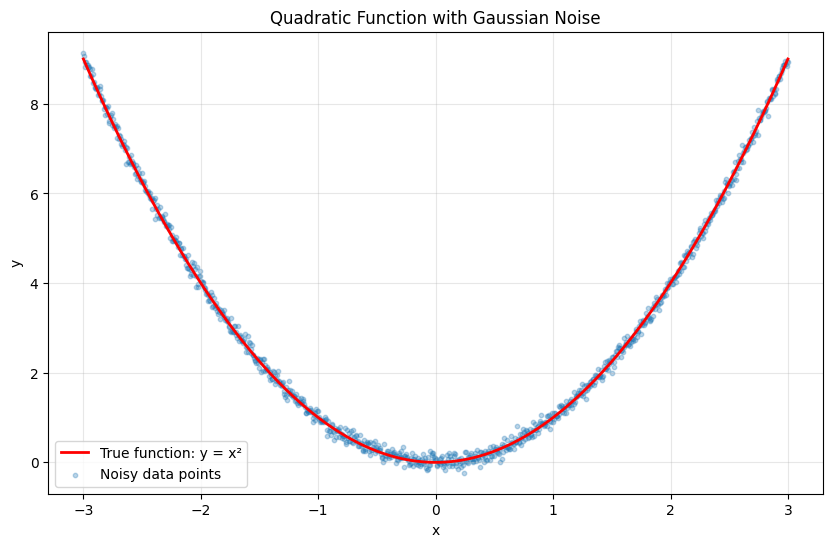

In [2]:
import matplotlib.pyplot as plt

# 生成数据
X = np.linspace(-3, 3, 1000)
y_true = X**2
y_noisy = X**2 + 0.1 * np.random.randn(1000)

plt.figure(figsize=(10, 6))
plt.plot(X, y_true, 'r-', label='True function: y = x²', linewidth=2)
plt.scatter(X, y_noisy, alpha=0.3, s=10, label='Noisy data points')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Quadratic Function with Gaussian Noise')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()